### Industrial Predicitive Maintenance

In [1]:
import sys
 
print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: C:\Users\10163815\AppData\Local\anaconda3\python.exe
Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


#### Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
 
print("All libraries imported successfully!")

All libraries imported successfully!


#### Load the data

In [3]:
data_path = r"C:\Users\10163815\PycharmProjects\industrial-predictive-maintenance\data\raw\ai4i2020.csv"
df = pd.read_csv(data_path)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


#### Dataset Overview

In [5]:
print("Dataset Shape:", df.shape)
 
print("\nColumn Names:")
print(df.columns.tolist())
 
print("\nDataset Information:")
df.info()
 
print("\nStatistical Summary:")
display(df.describe().T)

Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


#### Data quality checks

In [7]:
print("Missing Values:")
display(df.isnull().sum())
 
print("Total Missing Values:", df.isnull().sum().sum())
 
print("Duplicate Rows:", df.duplicated().sum())
 
print("Unique Values:")
display(df.nunique())

Missing Values:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total Missing Values: 0
Duplicate Rows: 0
Unique Values:


UDI                        10000
Product ID                 10000
Type                           3
Air temperature [K]           93
Process temperature [K]       82
Rotational speed [rpm]       941
Torque [Nm]                  577
Tool wear [min]              246
Machine failure                2
TWF                            2
HDF                            2
PWF                            2
OSF                            2
RNF                            2
dtype: int64

There are no missing or duplicate values

#### Understanding machine failure distribution

As this is a classification problem:
1. 0 = Machine did not fail
2. 1 = Machine failure occured

In [8]:
failure_counts = df["Machine failure"].value_counts()
 
print(failure_counts)
 
print("\nFailure Percentage:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


#### Visualizing Machine Failure Distribution

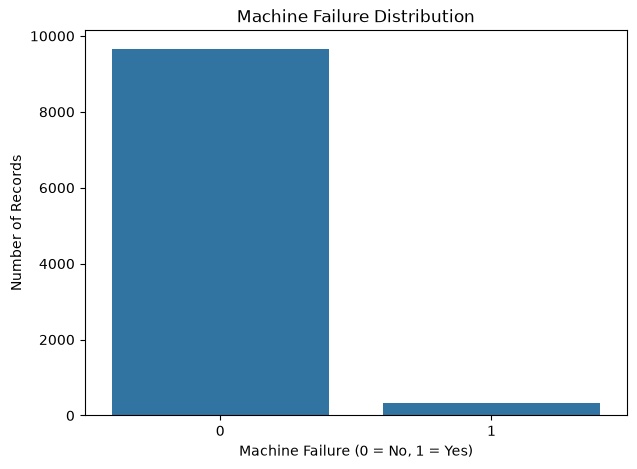

In [9]:
plt.figure(figsize=(7, 5))
 
sns.countplot(
    data=df,
    x="Machine failure"
)
 
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
 
plt.show()

The dataset has significant class imbalance. Accuracy alone is not a reliable evaluation metric

#### Analyzing sensor distributions

There are five important sensor features:
1. Air temperature
2. Process temperature
3. Rotational speed
4. Torque
5. Tool wear

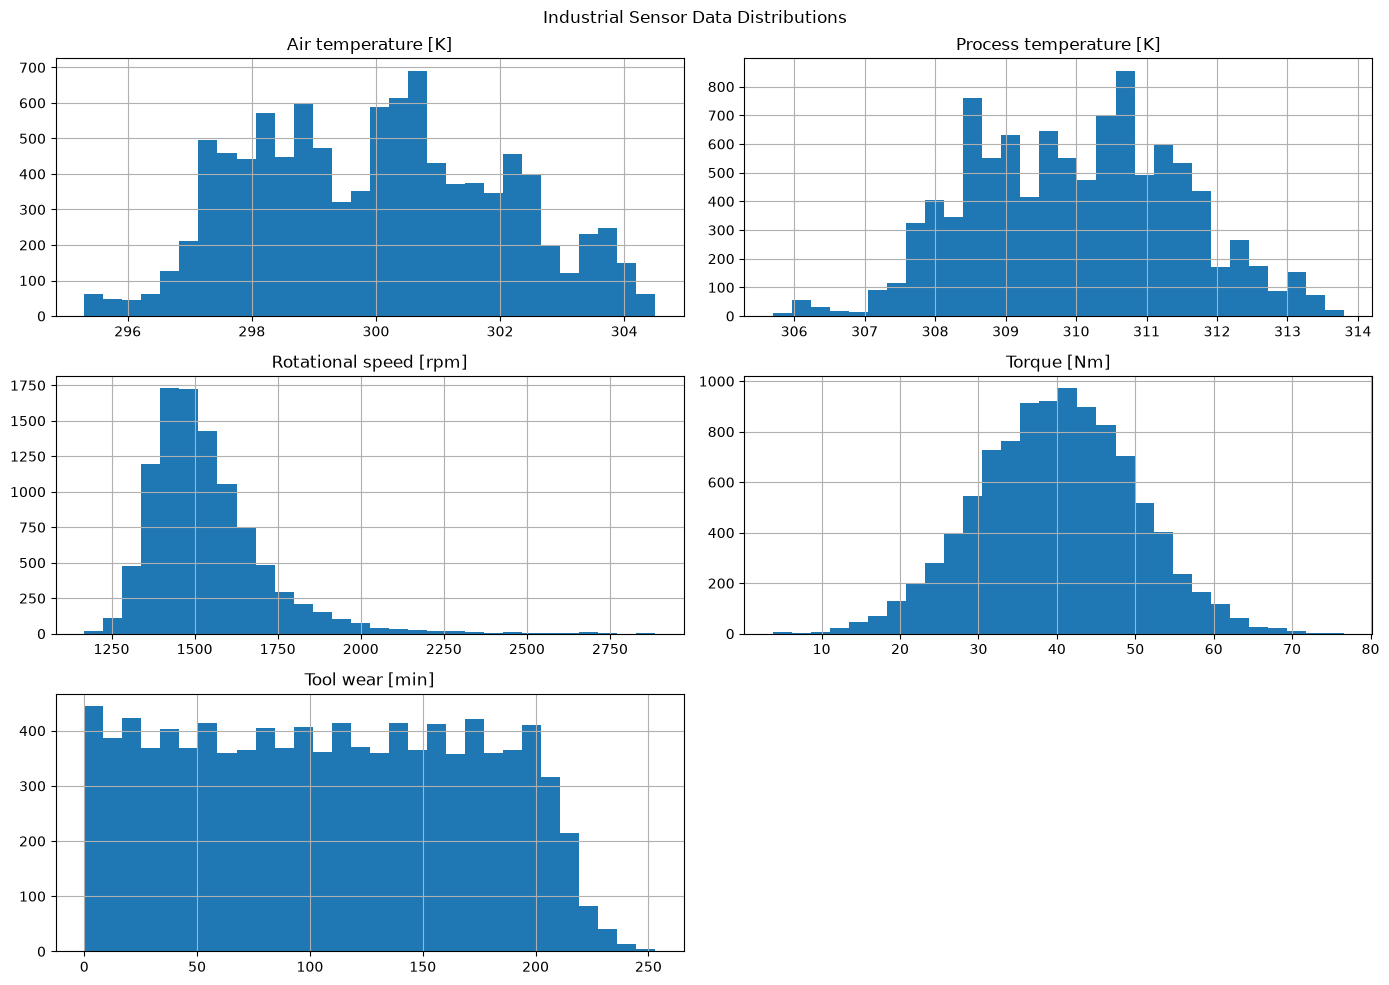

In [11]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
 
df[sensor_columns].hist(
    figsize=(14, 10),
    bins=30
)
 
plt.suptitle("Industrial Sensor Data Distributions")
plt.tight_layout()
plt.show()

Summary: 
1. Air temp and process temp are roughly bell shaped that is, normally distributed
2. Rotational speed is right-skewed that is Most values are concentrated at lower speeds, with a longer tail towards higher speeds
3. Torque is approximately normal with some deviation
4. Tool wear is approximately uniform


#### Sensor behaviour Vs Machine Failure

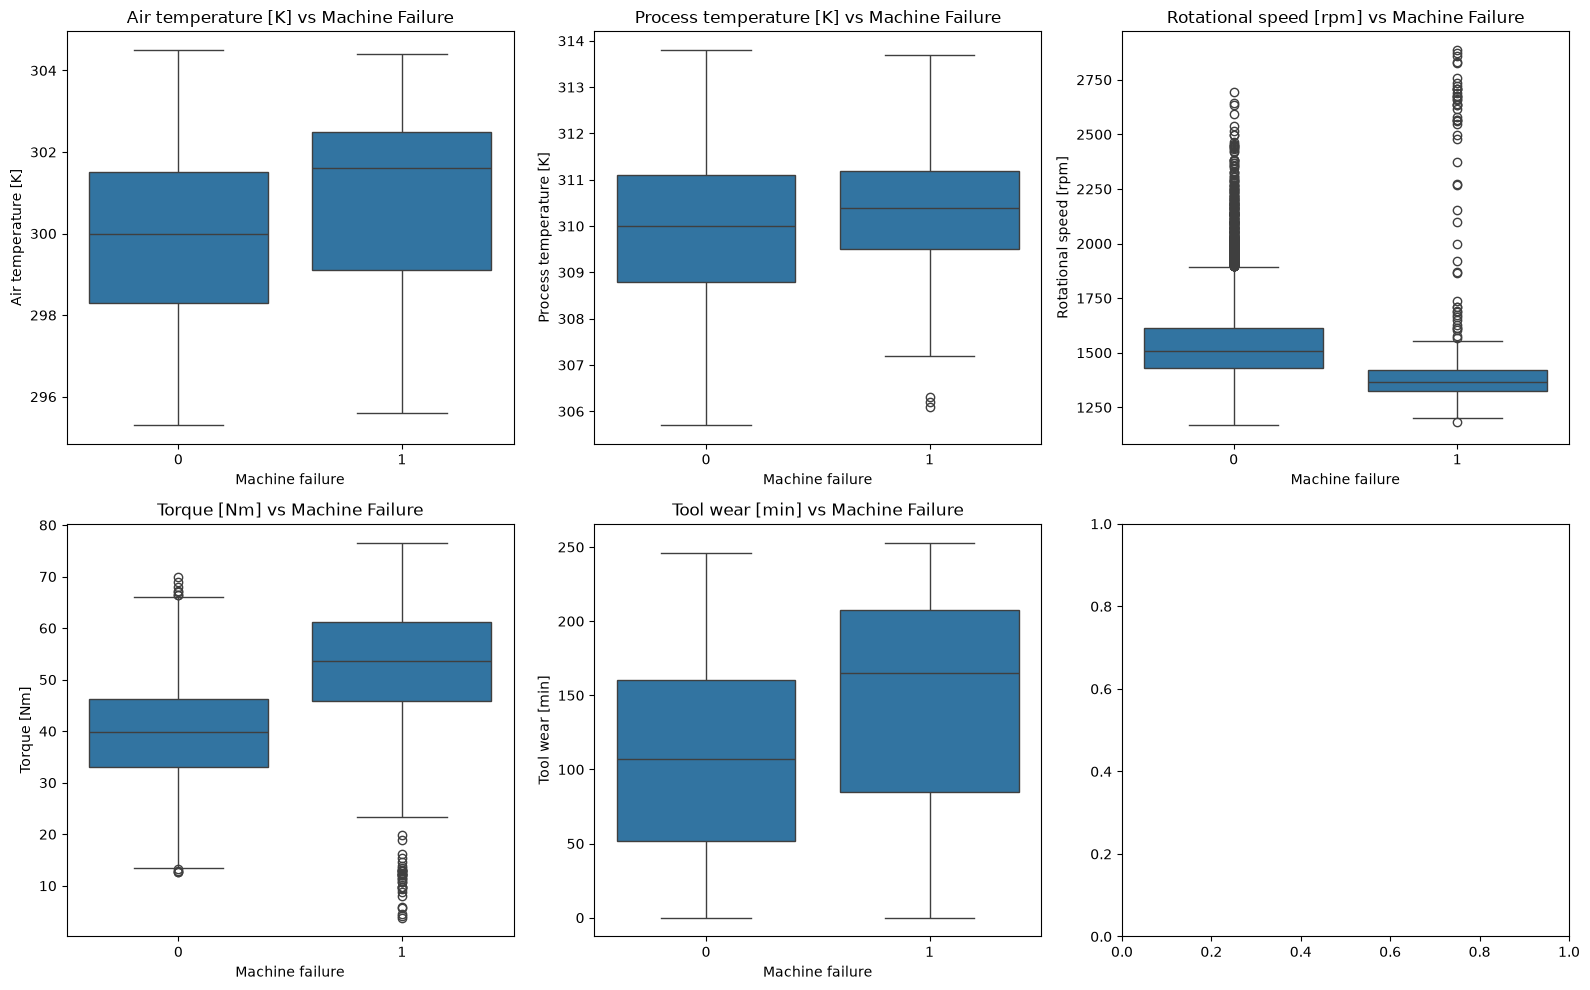

In [12]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
 
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
 
for ax, column in zip(axes.flatten(), sensor_columns):
 
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        ax=ax
    )
 
    ax.set_title(f"{column} vs Machine Failure")
 
plt.tight_layout()
plt.show()

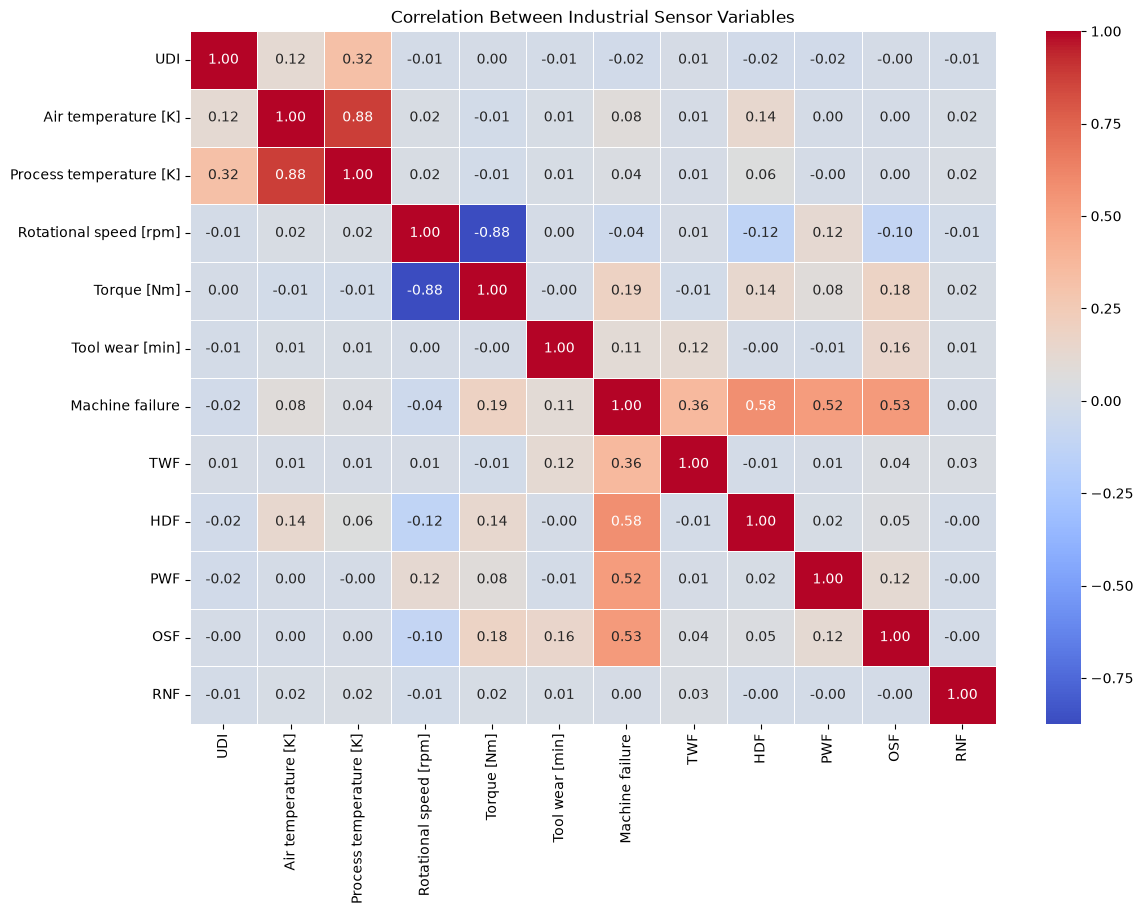

In [13]:
numeric_df = df.select_dtypes(include=np.number)
 
correlation = numeric_df.corr()
 
plt.figure(figsize=(13, 9))
 
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
 
plt.title("Correlation Between Industrial Sensor Variables")
plt.show()

1. Air temperature and process temperature: Expected positive correlation because process temperature is influenced by ambient temperature.
2. Rotational speed and torque: Expected negative relationship in this dataset.
3. Temperature and mechanical variables: Generally weaker linear relationships.